In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 3.3 — Coalgebra and bialgebra diagrams

**Source:** SMSA 7.8, 2026-11-05, §§3.3.1–3.3.2, §§3.3.4–3.3.5, §§3.3.9–3.3.14, §3.3.21; equations (3.47), (3.50), (3.60)–(3.65), (3.70)–(3.72). Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

The middle crossing in the bialgebra diagram becomes `Id(A) @ Swap(A, A) @ Id(A)`: it exchanges only the second and third of four wires. This spells out the unchanged outer wires in SMSA. It is a symmetric flip, with no over/under distinction (§3.3.12). We supply the group-algebra coefficients for $\mathbb Z_2$ and use native tensor evaluation.

In [1]:
from discopy import symmetric, tensor
from discopy.drawing import Equation
import numpy as np

In [2]:
A = symmetric.Ty('A')
mu = symmetric.Box('mu', A @ A, A)
eta = symmetric.Box('eta', symmetric.Ty(), A)
Delta = symmetric.Box('Delta', A, A @ A)
epsilon = symmetric.Box('epsilon', A, symmetric.Ty())
s = symmetric.Box('s', A, A)
I = symmetric.Id(A)
# Basis order: b_0, b_1 for the additive group Z_2; input indices precede output indices.
F = tensor.Functor(
    {A: 2},
    {mu: [[[int(k == (i + j) % 2) for k in range(2)] for j in range(2)] for i in range(2)],
     eta: [1, 0],
     Delta: [[[int(i == j == k) for k in range(2)] for j in range(2)] for i in range(2)],
     epsilon: [1, 1], s: [[1, 0], [0, 1]]},
    dom=symmetric.Category(), dtype=int)


(3.60) direct map, flattened inputs/outputs:
 [[1 0 0 0]
 [0 0 0 1]
 [0 0 0 1]
 [1 0 0 0]]
Expanded map:
 [[1 0 0 0]
 [0 0 0 1]
 [0 0 0 1]
 [1 0 0 0]]
Exact model equality: True


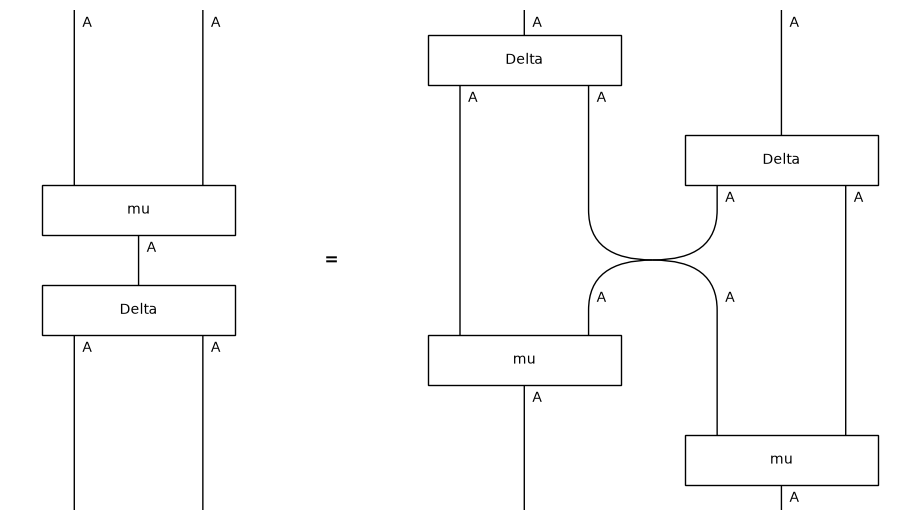

In [3]:
direct = mu >> Delta
expanded = (Delta @ Delta) >> (I @ symmetric.Swap(A, A) @ I) >> (mu @ mu)
Equation(direct, expanded).draw(figsize=(9, 5))
print('(3.60) direct map, flattened inputs/outputs:\n', F(direct).array.reshape(4, 4))
print('Expanded map:\n', F(expanded).array.reshape(4, 4))
print('Exact model equality:', F(direct) == F(expanded))

In [4]:
pairs = [
    ('(3.47) left counit', Delta >> (epsilon @ I), I),
    ('(3.47) right counit', Delta >> (I @ epsilon), I),
    ('(3.50) coassociativity', Delta >> (Delta @ I), Delta >> (I @ Delta)),
    ('(3.61) unit compatibility', eta >> Delta, eta @ eta),
    ('(3.62) counit of product', mu >> epsilon, epsilon @ epsilon),
    ('(3.62) counit of unit', eta >> epsilon, symmetric.Id(symmetric.Ty()))]
for label, left, right in pairs:
    print(label, '\nActual:', F(left).array, '\nExpected:', F(right).array, '\nEqual:', F(left) == F(right))

(3.47) left counit 
Actual: [[1 0]
 [0 1]] 
Expected: [[1 0]
 [0 1]] 
Equal: True
(3.47) right counit 
Actual: [[1 0]
 [0 1]] 
Expected: [[1 0]
 [0 1]] 
Equal: True
(3.50) coassociativity 
Actual: [[[[1 0]
   [0 0]]

  [[0 0]
   [0 0]]]


 [[[0 0]
   [0 0]]

  [[0 0]
   [0 1]]]] 
Expected: [[[[1 0]
   [0 0]]

  [[0 0]
   [0 0]]]


 [[[0 0]
   [0 0]]

  [[0 0]
   [0 1]]]] 
Equal: True
(3.61) unit compatibility 
Actual: [[1 0]
 [0 0]] 
Expected: [[1 0]
 [0 0]] 
Equal: True
(3.62) counit of product 
Actual: [[1 1]
 [1 1]] 
Expected: [[1 1]
 [1 1]] 
Equal: True
(3.62) counit of unit 
Actual: 1 
Expected: 1 
Equal: True


**The dual coalgebra, Example 3.3.4 and Task 3.3.5.** For a finite-dimensional algebra $(A,\mu,\eta)$ the dual space $A^*$ is a coalgebra. The task's hint is to use evaluation and coevaluation, and that is exactly what the library's `transpose(left=True)` does to a box: it bends both wires of $\mu$ round with a cup and a cap, so $\Delta^*=\mu^{\mathsf T}\colon A^*\to A^*\otimes A^*$ and $\varepsilon^*=\eta^{\mathsf T}\colon A^*\to\mathbb F$. As in §2.5, $A^*$ is the type `A.l`. In coordinates, $\Delta^*(\beta^k)$ has the coefficient $\beta^k(b_j\,b_i)$ in front of $\beta^i\otimes\beta^j$: the bends reverse the order of the two factors, because $(A\otimes A)^*$ is $A^*\otimes A^*$ with the factors swapped. To see this the product must be non-commutative, so the model here is the group algebra of $S_3$, six basis vectors $b_p$ labelled by permutations, $b_p\,b_q=b_{p\circ q}$. The cells print $\Delta^*$ against both candidate formulas, then check coassociativity and the counit laws of the dual structure. These are finite-model evaluations; no source axiom is assumed beyond the supplied multiplication table.

S3 is non-commutative: True
Delta* : A.l -> A.l @ A.l    eps* : A.l -> Ty()
Delta*(beta^k) coefficient of beta^i x beta^j equals beta^k(b_i b_j): False
equals beta^k(b_j b_i), factors reversed by the bends: True
eps* coefficients: [1 0 0 0 0 0]   expected: the coefficients of the unit element, True
coassociativity of Delta*: True
counit laws of eps*: True True


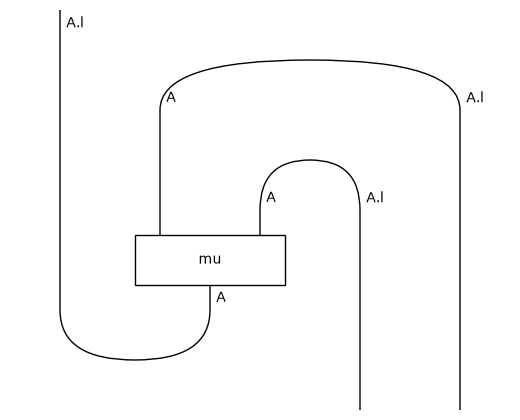

In [5]:
from discopy import rigid
import itertools
perms = list(itertools.permutations(range(3)))                       # S3, element p sends i to p[i]
prod = [[perms.index(tuple(p[q[i]] for i in range(3))) for q in perms] for p in perms]   # prod[a][b]: index of p_a o p_b
unit_index = perms.index((0, 1, 2))
n = 6
mu_S3 = [[[int(k == prod[i][j]) for k in range(n)] for j in range(n)] for i in range(n)]
eta_S3 = [int(k == unit_index) for k in range(n)]
print('S3 is non-commutative:', any(prod[a][b] != prod[b][a] for a in range(n) for b in range(n)))
Ar = rigid.Ty('A')
mu_r = rigid.Box('mu', Ar @ Ar, Ar)
eta_r = rigid.Box('eta', rigid.Ty(), Ar)
Delta_star = mu_r.transpose(left=True)
eps_star = eta_r.transpose(left=True)
print('Delta* :', Delta_star.dom, '->', Delta_star.cod, '   eps* :', eps_star.dom, '->', eps_star.cod)
R = tensor.Functor({Ar: n}, {mu_r: mu_S3, eta_r: eta_S3}, dom=rigid.Category(), dtype=int)
D = R(Delta_star).array
same_order = np.array([[[int(k == prod[i][j]) for j in range(n)] for i in range(n)] for k in range(n)])
swapped = np.array([[[int(k == prod[j][i]) for j in range(n)] for i in range(n)] for k in range(n)])
print('Delta*(beta^k) coefficient of beta^i x beta^j equals beta^k(b_i b_j):', np.array_equal(D, same_order))
print('equals beta^k(b_j b_i), factors reversed by the bends:', np.array_equal(D, swapped))
print('eps* coefficients:', R(eps_star).array, '  expected: the coefficients of the unit element,', np.array_equal(R(eps_star).array, np.array(eta_S3)))
Il = rigid.Id(Ar.l)
print('coassociativity of Delta*:', R(Delta_star >> (Delta_star @ Il)) == R(Delta_star >> (Il @ Delta_star)))
print('counit laws of eps*:', R(Delta_star >> (eps_star @ Il)) == R(Il), R(Delta_star >> (Il @ eps_star)) == R(Il))
Delta_star.draw(figsize=(5, 4))

**Convolution, Homework 3.3.21.** The tensor product $A\otimes A$ is a coalgebra with the coproduct $(\mathrm{id}\otimes\tau\otimes\mathrm{id})\circ(\Delta\otimes\Delta)$, the same middle crossing as in (3.60). Linear maps $\varphi,\varphi'\colon A\otimes A\to A$ then have the convolution product (3.71), $\varphi\circledast\varphi'=\mu\circ(\varphi\otimes\varphi')\circ\Delta_{A\otimes A}$, with unit $\eta\circ(\varepsilon\otimes\varepsilon)$. The homework asks to show (3.72), that $s\circ\mu$ and $\mu\circ\tau\circ(s\otimes s)$ are a left and a right convolution inverse of $\mu$, and then to use a general property of inverses to conclude the anti-homomorphism law (3.70). The cells below evaluate the two sides of (3.72), the unit property and (3.70) itself in the group algebra of $S_3$, with $s$ the inversion of permutations, and show that (3.70) fails if the flip $\tau$ is left out. These are instances in one model. The last step of the homework, that an element with a left and a right inverse in an associative unital algebra has a single two-sided inverse, is the reader's to supply, as the source asks; nothing here derives it.

(3.72) (s o mu) * mu == unit: True
(3.72) mu * (mu o tau o (s x s)) == unit: True
unit property, unit * mu == mu and mu * unit == mu: True True
(3.70) s o mu == mu o tau o (s x s): True
control, without the flip: s o mu == mu o (s x s): False
entries of (s o mu) * mu, flattened 36 x 6, first rows:
[[1 0 0 0 0 0]
 [1 0 0 0 0 0]
 [1 0 0 0 0 0]
 [1 0 0 0 0 0]]
entries of the convolution unit, first rows:
[[1 0 0 0 0 0]
 [1 0 0 0 0 0]
 [1 0 0 0 0 0]
 [1 0 0 0 0 0]]


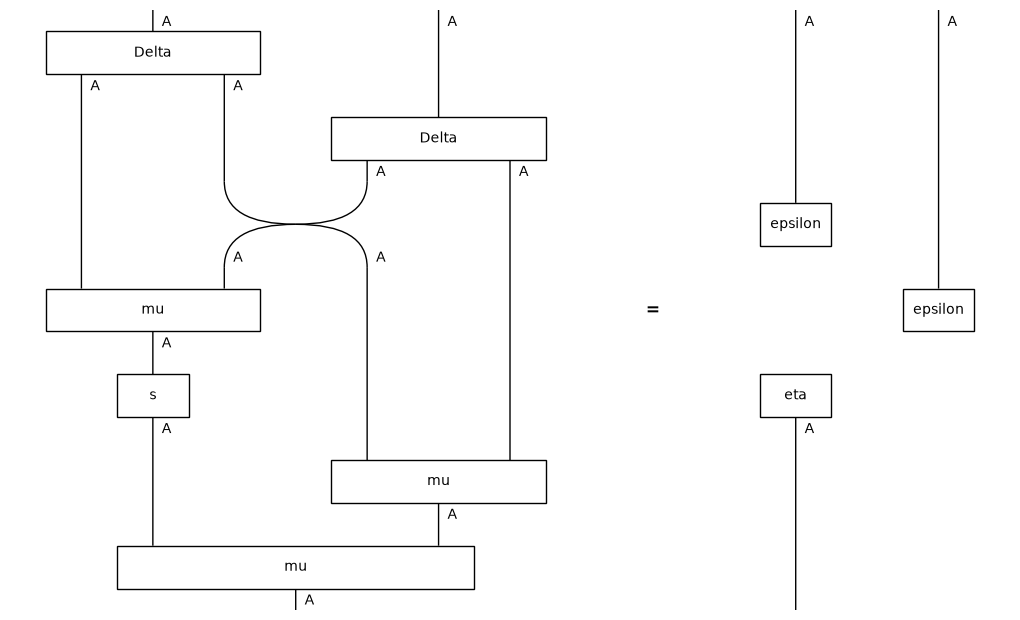

In [6]:
inv = [[j for j in range(n) if prod[i][j] == unit_index][0] for i in range(n)]   # index of the inverse permutation
Delta_S3 = [[[int(i == j == k) for k in range(n)] for j in range(n)] for i in range(n)]
eps_S3 = [1] * n
s_S3 = [[int(j == inv[i]) for j in range(n)] for i in range(n)]
H = tensor.Functor({A: n}, {mu: mu_S3, eta: eta_S3, Delta: Delta_S3, epsilon: eps_S3, s: s_S3}, dom=symmetric.Category(), dtype=int)
Delta_AA = (Delta @ Delta) >> (I @ symmetric.Swap(A, A) @ I)          # coproduct of A tensor A
s_after_mu = mu >> s                                                  # s o mu
mu_after_flip = (s @ s) >> symmetric.Swap(A, A) >> mu                 # mu o tau o (s x s)
unit_conv = (epsilon @ epsilon) >> eta                                # eta o (eps x eps)
left_conv = Delta_AA >> (s_after_mu @ mu) >> mu                       # (s o mu) * mu
right_conv = Delta_AA >> (mu @ mu_after_flip) >> mu                   # mu * (mu o tau o (s x s))
print('(3.72) (s o mu) * mu == unit:', H(left_conv) == H(unit_conv))
print('(3.72) mu * (mu o tau o (s x s)) == unit:', H(right_conv) == H(unit_conv))
print('unit property, unit * mu == mu and mu * unit == mu:', H(Delta_AA >> (unit_conv @ mu) >> mu) == H(mu), H(Delta_AA >> (mu @ unit_conv) >> mu) == H(mu))
print('(3.70) s o mu == mu o tau o (s x s):', H(s_after_mu) == H(mu_after_flip))
print('control, without the flip: s o mu == mu o (s x s):', H(s_after_mu) == H((s @ s) >> mu))
print('entries of (s o mu) * mu, flattened 36 x 6, first rows:')
print(H(left_conv).array.reshape(36, 6)[:4])
print('entries of the convolution unit, first rows:')
print(H(unit_conv).array.reshape(36, 6)[:4])
Equation(left_conv, unit_conv, symbol='=').draw(figsize=(10, 6))

**Scope.** The dual coalgebra of §3.3.5 is built by the native transpose and verified in $S_3$, including the factor reversal that the bends introduce. The convolution identities (3.72), their unit, and the anti-homomorphism (3.70) are evaluated in the same model, with a failing control without the flip. The general proofs are SMSA's homework; no Hopf rewrite rules are supplied by the boxes.